# MODULO ECONOMICO

In [1]:
# ── CELLA 1 · Contratto dati: cosa il Modulo E si aspetta dalle Fasi 2–4 ──────────
# Nessuna dipendenza da altre celle.
import numpy as np
import pandas as pd

SEGMENT_SCHEMA = {
    "route_id":   "identificativo rotta (Fase 2 / Modulo F)",
    "seg_id":     "indice progressivo del segmento lungo la rotta",
    "lon":        "longitudine del centro segmento [deg]",
    "lat":        "latitudine del centro segmento [deg]",
    "s":          "P(evento pericoloso sul segmento | un transito)            — Fase 2",
    "h_fc":       "hit rate della previsione CMEMS sugli eventi (1 − sottostimati) — Fase 3 / H3",
    "f_fc":       "false alarm rate della previsione CMEMS                     — Fase 3",
    "fuel_pen_t": "penalità carburante di una singola azione di evitamento [t]  — Fase 4",
}
ROUTE_SCHEMA = {
    "route_id":               "come sopra",
    "transits_per_ship_year": "transiti per nave per anno sulla rotta",
}
COVERAGE_PREFIX = "pcov_"   # una colonna per missione: P(passaggio entro (Δt, Δx) | transito) — Fase 3 / Modulo B


def validate_segments(seg: pd.DataFrame) -> pd.DataFrame:
    """Controlla schema e range; restituisce una copia ordinata."""
    missing = [c for c in SEGMENT_SCHEMA if c not in seg.columns]
    if missing:
        raise ValueError(f"Colonne mancanti: {missing}")
    cov_cols = [c for c in seg.columns if c.startswith(COVERAGE_PREFIX)]
    if not cov_cols:
        raise ValueError(f"Serve almeno una colonna '{COVERAGE_PREFIX}<missione>'")
    prob_cols = ["s", "h_fc", "f_fc"] + cov_cols
    bad = [c for c in prob_cols if not seg[c].between(0, 1).all()]
    if bad:
        raise ValueError(f"Probabilità fuori da [0,1] in: {bad}")
    if (seg["fuel_pen_t"] < 0).any():
        raise ValueError("fuel_pen_t non può essere negativa")
    return seg.sort_values(["route_id", "seg_id"]).reset_index(drop=True).copy()


def validate_routes(routes: pd.DataFrame, seg: pd.DataFrame) -> pd.DataFrame:
    missing = [c for c in ROUTE_SCHEMA if c not in routes.columns]
    if missing:
        raise ValueError(f"Colonne mancanti: {missing}")
    orphan = set(seg["route_id"]) - set(routes["route_id"])
    if orphan:
        raise ValueError(f"Rotte nei segmenti ma non in routes: {orphan}")
    return routes.set_index("route_id").copy()


def list_missions(seg: pd.DataFrame) -> list[str]:
    return [c[len(COVERAGE_PREFIX):] for c in seg.columns if c.startswith(COVERAGE_PREFIX)]

In [2]:
# ── CELLA 2 · Dati SINTETICI segnaposto (solo per far girare le celle) ────────────
# Da sostituire con gli output reali delle Fasi 2–4 rispettando lo schema della Cella 1.
# Nessuna dipendenza da altre celle.
import numpy as np
import pandas as pd


def make_synthetic_inputs(n_seg: int = 40,
                          routes: tuple = ("LIS-HFX_orto", "LIS-HFX_nord"),
                          seed: int = 0):
    rng = np.random.default_rng(seed)
    lon0, lat0, lon1, lat1 = -9.1, 38.7, -63.6, 44.6          # Lisbona → Halifax
    frames = []
    for k, r in enumerate(routes):
        t = np.linspace(0, 1, n_seg)
        lon = lon0 + (lon1 - lon0) * t
        lat = lat0 + (lat1 - lat0) * t + 2.5 * k * np.sin(np.pi * t)   # variante più a nord
        gb = np.exp(-((lon + 50) / 6) ** 2)                            # ~Grand Banks / Flemish Cap
        frames.append(pd.DataFrame({
            "route_id": r, "seg_id": np.arange(n_seg), "lon": lon, "lat": lat,
            "s":          np.clip(0.004 + (0.010 + 0.004 * k) * np.sin(np.pi * t)
                                  + rng.normal(0, 0.001, n_seg), 0, 1),
            "h_fc":       np.clip(0.60 + rng.normal(0, 0.05, n_seg), 0, 1),
            "f_fc":       np.clip(0.02 + rng.normal(0, 0.005, n_seg), 0, 1),
            "fuel_pen_t": np.clip(3.0 + rng.normal(0, 0.5, n_seg), 0, None),
            "pcov_S1":    np.clip(0.03 + 0.25 * gb, 0, 1),      # SAR denso solo sui Grand Banks (H2)
            "pcov_S3":    np.full(n_seg, 0.05),
            "pcov_S6":    np.full(n_seg, 0.03),
            "pcov_CS2":   np.full(n_seg, 0.03),
        }))
    seg = pd.concat(frames, ignore_index=True)
    routes_df = pd.DataFrame({"route_id": list(routes),
                              "transits_per_ship_year": [20] * len(routes)})
    return seg, routes_df

In [3]:
# ── CELLA 3 · Parametri economici con incertezza (triangolare low / mode / high) ──
# TUTTI i valori di default sono SEGNAPOSTO: vanno sostituiti con intervalli tratti da
# Allianz [9], World Shipping Council, prezzi bunker correnti, preventivi di servizio.
# Nessuna dipendenza da altre celle.
from dataclasses import dataclass, fields, replace
import numpy as np


@dataclass(frozen=True)
class Tri:
    low: float
    mode: float
    high: float

    def sample(self, rng, n):
        return rng.triangular(self.low, self.mode, self.high, n)


@dataclass(frozen=True)
class EconParams:
    fuel_price_usd_t:  Tri = Tri(500, 600, 750)       # prezzo combustibile [USD/t]
    p_incident:        Tri = Tri(0.01, 0.05, 0.15)    # P(danno | evento NON mitigato)
    consequence_usd:   Tri = Tri(2e5, 1e6, 1e7)       # danno medio per incidente (carico, container, scafo)
    eta:               Tri = Tri(0.5, 0.7, 0.9)       # frazione di danno evitata agendo
    f_sat:             Tri = Tri(0.01, 0.03, 0.08)    # falsi allarmi per passaggio satellitare
    p_act:             Tri = Tri(0.2, 0.4, 0.6)       # frazione di rilevazioni arrivate in tempo (latenza)
    fixed_cost_usd_yr: Tri = Tri(1e5, 3e5, 8e5)       # catena a terra + centro di allerta [USD/anno, flotta]
    var_cost_usd_tr:   Tri = Tri(50, 150, 400)        # satcom / abbonamento [USD/transito]

    def point(self, which: str = "mode") -> dict:
        """Dizionario di scalari: which ∈ {'low','mode','high'}."""
        return {f.name: getattr(getattr(self, f.name), which) for f in fields(self)}

    def sample(self, n: int, seed: int = 0) -> dict:
        """Dizionario di array (n,) per il Monte Carlo."""
        rng = np.random.default_rng(seed)
        return {f.name: getattr(self, f.name).sample(rng, n) for f in fields(self)}

    def with_(self, **kw) -> "EconParams":
        """Copia con alcuni parametri sostituiti (es. scenari di latenza dalla UI)."""
        return replace(self, **kw)

In [4]:
# ── CELLA 4 · Copertura combinata di un insieme di missioni ───────────────────────
# Dipende solo dalla convenzione di nome 'pcov_<missione>'.
# Ipotesi: passaggi indipendenti tra missioni → 1 − Π(1 − p_m).
# Se la Fase 3 calcola l'unione empirica, passala in 'empirical_col' e verrà usata quella.
import numpy as np
import pandas as pd


def combined_coverage(seg: pd.DataFrame, missions: list[str] | None,
                      empirical_col: str | None = None) -> np.ndarray:
    if empirical_col is not None:
        return seg[empirical_col].to_numpy(dtype=float)
    if not missions:
        return np.zeros(len(seg))
    cols = [f"pcov_{m}" for m in missions]
    missing = [c for c in cols if c not in seg.columns]
    if missing:
        raise ValueError(f"Missioni non presenti nei dati: {missing}")
    return 1.0 - np.prod(1.0 - seg[cols].to_numpy(dtype=float), axis=1)

In [5]:
# ── CELLA 5 · Motore: valore per segmento e per transito (rispetto a "solo previsione") ─
# Funzione pura, numpy-broadcastable: accetta parametri scalari (dict da .point())
# oppure array (n,) (dict da .sample()) → output (n_seg,) o (n_seg, n).
#
#   ΔH  = (1 − h_fc) · cov · p_act          eventi mancati dalla previsione e recuperati in tempo
#   ΔF  = cov · f_sat                       falsi allarmi aggiuntivi
#   C   = fuel_pen_t · fuel_price           costo di un'azione
#   L   = p_incident · consequence          perdita attesa di un evento non mitigato
#   beneficio   = s · ΔH · η · L
#   costo_azioni = [s · ΔH + (1 − s) · ΔF] · C
#   netto_segmento = beneficio − costo_azioni      (costi di servizio esclusi: vedi Cella 7)
import numpy as np
import pandas as pd


def _segment_terms(s, h_fc, fuel_pen_t, cov, p: dict) -> dict:
    as_col = lambda x: np.asarray(x, dtype=float)[:, None]
    as_row = lambda x: np.atleast_1d(np.asarray(x, dtype=float))[None, :]
    s, h_fc, fuel_pen_t, cov = map(as_col, (s, h_fc, fuel_pen_t, cov))
    dH = (1 - h_fc) * cov * as_row(p["p_act"])
    dF = cov * as_row(p["f_sat"])
    C = fuel_pen_t * as_row(p["fuel_price_usd_t"])
    L = as_row(p["p_incident"]) * as_row(p["consequence_usd"])
    s_dH = s * dH
    benefit = s_dH * as_row(p["eta"]) * L
    act_cost = (s_dH + (1 - s) * dF) * C
    out = {"cov": cov, "dH": dH, "dF": dF, "s_dH": s_dH,
           "benefit": benefit, "act_cost": act_cost, "net": benefit - act_cost}
    return {k: (v[:, 0] if v.shape[1] == 1 else v) for k, v in out.items()}


def segment_value(seg: pd.DataFrame, missions: list[str], p: dict,
                  empirical_col: str | None = None) -> pd.DataFrame:
    """Parametri scalari → tabella per segmento (base per la mappa dell'atlante)."""
    cov = combined_coverage(seg, missions, empirical_col)
    t = _segment_terms(seg["s"], seg["h_fc"], seg["fuel_pen_t"], cov, p)
    out = seg[["route_id", "seg_id", "lon", "lat", "s"]].copy()
    for k in ("cov", "dH", "dF", "s_dH", "benefit", "act_cost", "net"):
        out[k] = t[k]
    return out

In [6]:
# ── CELLA 6 · Aggregazione per rotta (valore per transito) ────────────────────────
# Input: output di segment_value (Cella 5).
import numpy as np
import pandas as pd


def route_summary(seg_val: pd.DataFrame, blind_cov_threshold: float = 0.05) -> pd.DataFrame:
    """Somma per rotta. 'blind' = segmenti con copertura sotto soglia (corridoio cieco, H2)."""
    sv = seg_val.assign(blind=seg_val["cov"] < blind_cov_threshold)
    g = sv.groupby("route_id")
    out = pd.DataFrame({
        "n_seg":           g.size(),
        "hazard_per_tr":   g["s"].sum(),                       # n. atteso eventi per transito
        "s_dH":            g["s_dH"].sum(),                    # eventi recuperati per transito
        "benefit_usd_tr":  g["benefit"].sum(),
        "act_cost_usd_tr": g["act_cost"].sum(),
        "net_usd_tr":      g["net"].sum(),
        "blind_share_seg": g["blind"].mean(),
        "blind_share_hazard": sv.assign(hb=sv["s"] * sv["blind"]).groupby("route_id")["hb"].sum()
                              / g["s"].sum(),
    })
    return out

In [7]:
# ── CELLA 7 · Scala di flotta: costi fissi vs benefici lineari, N* di pareggio ────
# Input: route_summary (Cella 6), routes validato (Cella 1), parametri scalari.
#   margine per nave/anno  m = Σ_r w_r · T_r · (netto_r − costo_var)
#   netto flotta/anno      = N · m − costo_fisso         →   N* = costo_fisso / m
import numpy as np
import pandas as pd


def _mix(route_ids, route_mix: dict | None) -> pd.Series:
    if route_mix is None:
        return pd.Series(1.0 / len(route_ids), index=route_ids)
    w = pd.Series(route_mix, dtype=float).reindex(route_ids).fillna(0.0)
    if w.sum() <= 0:
        raise ValueError("route_mix con pesi nulli")
    return w / w.sum()


def per_ship_margin(rs: pd.DataFrame, routes: pd.DataFrame, p: dict,
                    route_mix: dict | None = None) -> float:
    w = _mix(rs.index, route_mix)
    T = routes.loc[rs.index, "transits_per_ship_year"]
    return float((w * T * (rs["net_usd_tr"] - p["var_cost_usd_tr"])).sum())


def fleet_curve(rs: pd.DataFrame, routes: pd.DataFrame, p: dict,
                n_ships=np.arange(1, 201), route_mix: dict | None = None) -> pd.DataFrame:
    n = np.asarray(n_ships, dtype=float)
    m = per_ship_margin(rs, routes, p, route_mix)
    w = _mix(rs.index, route_mix)
    T_bar = float((w * routes.loc[rs.index, "transits_per_ship_year"]).sum())
    return pd.DataFrame({
        "n_ships": n,
        "annual_net_usd": n * m - p["fixed_cost_usd_yr"],
        "service_cost_usd_tr": p["var_cost_usd_tr"] + p["fixed_cost_usd_yr"] / (n * T_bar),
        "gross_net_usd_tr": float((w * rs["net_usd_tr"]).sum()),   # valore per transito prima del servizio
    })


def breakeven_fleet(rs, routes, p, route_mix=None) -> float:
    m = per_ship_margin(rs, routes, p, route_mix)
    return p["fixed_cost_usd_yr"] / m if m > 0 else np.inf


def fleet_annual_net(seg, routes, p, missions, n_ships, route_mix=None,
                     empirical_col=None) -> float:
    """Scorciatoia end-to-end deterministica (usata da tornado e curve missioni)."""
    rs = route_summary(segment_value(seg, missions, p, empirical_col))
    return n_ships * per_ship_margin(rs, routes, p, route_mix) - p["fixed_cost_usd_yr"]

In [8]:
# ── CELLA 8 · Analisi di pareggio: quanto deve valere la perdita evitata? ─────────
# Per ogni rotta risolve netto_transito = 0 rispetto a L (e quindi a p_incident):
#   L* = (Σ costo_azioni + costo_servizio_tr) / (η · Σ s·ΔH)
# Input: segment_value (Cella 5) calcolato con i parametri scelti.
import numpy as np
import pandas as pd


def breakeven_loss(seg_val: pd.DataFrame, routes: pd.DataFrame, p: dict,
                   n_ships: float, route_mix: dict | None = None) -> pd.DataFrame:
    g = seg_val.groupby("route_id")
    s_dH = g["s_dH"].sum()
    act = g["act_cost"].sum()
    T = routes.loc[s_dH.index, "transits_per_ship_year"]
    w = pd.Series(1.0 / len(s_dH), index=s_dH.index) if route_mix is None else \
        pd.Series(route_mix, dtype=float).reindex(s_dH.index).fillna(0) / sum(route_mix.values())
    T_bar = float((w * T).sum())
    serv = p["var_cost_usd_tr"] + p["fixed_cost_usd_yr"] / (n_ships * T_bar)
    with np.errstate(divide="ignore"):
        L_star = (act + serv) / (p["eta"] * s_dH)
    L_star = L_star.where(s_dH > 0, np.inf)
    return pd.DataFrame({
        "L_star_usd": L_star,                                   # perdita attesa minima per evento
        "p_incident_star": L_star / p["consequence_usd"],       # a parità di consequence
        "L_assumed_usd": p["p_incident"] * p["consequence_usd"],
        "margin_x": (p["p_incident"] * p["consequence_usd"]) / L_star,   # >1 = sopra il pareggio
    })

In [9]:
# ── CELLA 9 · Modello costo-perdita: valore economico relativo (Richardson 2000) ──
# Confronta previsione sola vs previsione + satellite su un insieme di segmenti.
# α = C / (η·L). V = (E_clim − E) / (E_clim − E_perfect), con
#   E = α(H·s̄ + F(1−s̄)) + s̄(1−H),  E_clim = min(α, s̄),  E_perfect = α·s̄
import numpy as np
import pandas as pd


def _rev(alpha, s, H, F):
    E_clim = np.minimum(alpha, s)
    E_perf = alpha * s
    E = alpha * (H * s + F * (1 - s)) + s * (1 - H)
    with np.errstate(divide="ignore", invalid="ignore"):
        return (E_clim - E) / (E_clim - E_perf)


def rev_curve(seg: pd.DataFrame, seg_val: pd.DataFrame,
              alphas=np.logspace(-3, 0, 200)) -> pd.DataFrame:
    """seg_val deve venire da segment_value sugli stessi segmenti (stesso ordine)."""
    s = seg["s"].to_numpy(); w_e = s / s.sum(); w_n = (1 - s) / (1 - s).sum()
    s_bar = s.mean()
    H_fc = float((w_e * seg["h_fc"]).sum())
    F_fc = float((w_n * seg["f_fc"]).sum())
    H_sat = H_fc + float((w_e * seg_val["dH"].to_numpy()).sum())
    F_sat = F_fc + float((w_n * seg_val["dF"].to_numpy()).sum())
    a = np.asarray(alphas)
    return pd.DataFrame({"alpha": a,
                         "V_forecast": _rev(a, s_bar, H_fc, F_fc),
                         "V_forecast_sat": _rev(a, s_bar, min(H_sat, 1), min(F_sat, 1))}) \
             .assign(dV=lambda d: d.V_forecast_sat - d.V_forecast)


def operating_alpha(seg: pd.DataFrame, p: dict) -> float:
    """α del problema reale: costo medio di un'azione / perdita evitabile."""
    C = float((seg["fuel_pen_t"] * p["fuel_price_usd_t"]).mean())
    return C / (p["eta"] * p["p_incident"] * p["consequence_usd"])

In [10]:
# ── CELLA 10 · Monte Carlo sull'incertezza dei parametri ──────────────────────────
# Usa _segment_terms (Cella 5) in modalità vettoriale: matrice (n_seg × n_campioni).
import numpy as np
import pandas as pd


def monte_carlo(seg, routes, params, missions, n_ships, n=5000, seed=0,
                route_mix=None, empirical_col=None) -> dict:
    S = params.sample(n, seed)
    cov = combined_coverage(seg, missions, empirical_col)
    t = _segment_terms(seg["s"], seg["h_fc"], seg["fuel_pen_t"], cov, S)
    codes, uniq = pd.factorize(seg["route_id"])
    net_r = np.zeros((len(uniq), n))
    np.add.at(net_r, codes, np.atleast_2d(t["net"]))
    w = _mix(pd.Index(uniq), route_mix).to_numpy()[:, None]
    T = routes.loc[uniq, "transits_per_ship_year"].to_numpy()[:, None]
    margin = (w * T * (net_r - S["var_cost_usd_tr"][None, :])).sum(axis=0)
    annual = n_ships * margin - S["fixed_cost_usd_yr"]
    with np.errstate(divide="ignore"):
        n_star = np.where(margin > 0, S["fixed_cost_usd_yr"] / margin, np.inf)
    per_route = pd.DataFrame(net_r.T, columns=uniq).melt(var_name="route_id",
                                                         value_name="net_usd_tr")
    q = lambda x: pd.Series(np.quantile(x, [0.05, 0.5, 0.95], method="inverted_cdf"),
                            index=["p05", "p50", "p95"])
    summary = pd.DataFrame({"annual_net_usd": q(annual),
                            "n_star_ships": q(n_star)}).T
    summary["P_positive"] = [float((annual > 0).mean()), float(np.isfinite(n_star).mean())]
    return {"samples": pd.DataFrame({"annual_net_usd": annual, "n_star": n_star, **S}),
            "per_route": per_route, "summary": summary}

In [11]:
# ── CELLA 11 · Sensitività a tornado (un parametro alla volta, low ↔ high) ────────
# Usa fleet_annual_net (Cella 7).
from dataclasses import fields
import pandas as pd


def tornado(seg, routes, params, missions, n_ships, route_mix=None) -> pd.DataFrame:
    base_p = params.point("mode")
    base = fleet_annual_net(seg, routes, base_p, missions, n_ships, route_mix)
    rows = []
    for f in fields(params):
        tri = getattr(params, f.name)
        lo = fleet_annual_net(seg, routes, {**base_p, f.name: tri.low}, missions, n_ships, route_mix)
        hi = fleet_annual_net(seg, routes, {**base_p, f.name: tri.high}, missions, n_ships, route_mix)
        rows.append({"param": f.name, "at_low": lo - base, "at_high": hi - base,
                     "swing": abs(hi - lo)})
    return pd.DataFrame(rows).sort_values("swing", ascending=False).assign(base=base) \
             .reset_index(drop=True)

In [12]:
# ── CELLA 12 · Curva economica della costellazione (Modulo B → €) ─────────────────
# Aggiunta greedy: a ogni passo la missione che aumenta di più il netto annuo di flotta.
import numpy as np
import pandas as pd


def mission_value_curve(seg, routes, p, missions_available, n_ships,
                        route_mix=None) -> pd.DataFrame:
    chosen, remaining = [], list(missions_available)
    prev = 0.0   # riferimento: solo previsione, nessun servizio acquistato
    rows = [{"step": 0, "added": "(solo previsione)", "missions": "", "annual_net_usd": prev,
             "marginal_usd": np.nan}]
    while remaining:
        scores = {m: fleet_annual_net(seg, routes, p, chosen + [m], n_ships, route_mix)
                  for m in remaining}
        best = max(scores, key=scores.get)
        chosen.append(best); remaining.remove(best)
        rows.append({"step": len(chosen), "added": best, "missions": "+".join(chosen),
                     "annual_net_usd": scores[best], "marginal_usd": scores[best] - prev})
        prev = scores[best]
    return pd.DataFrame(rows)

In [13]:
# ── CELLA 13 · Scenari di latenza (attuabilità del dato) ──────────────────────────
# Valori p_act SEGNAPOSTO: da calibrare sui tempi reali di consegna dei prodotti NRT.
import pandas as pd

LATENCY_SCENARIOS = {
    "NRT attuale":         Tri(0.2, 0.4, 0.6),
    "Catena dedicata":     Tri(0.5, 0.7, 0.85),
    "Ideale (istantaneo)": Tri(1.0, 1.0, 1.0),
}


def latency_table(seg, routes, params, missions, n_ships, route_mix=None,
                  scenarios=LATENCY_SCENARIOS) -> pd.DataFrame:
    rows = []
    for name, tri in scenarios.items():
        p = params.with_(p_act=tri).point("mode")
        rs = route_summary(segment_value(seg, missions, p))
        rows.append({"scenario": name, "p_act": tri.mode,
                     "annual_net_usd": fleet_annual_net(seg, routes, p, missions, n_ships, route_mix),
                     "n_star_ships": breakeven_fleet(rs, routes, p, route_mix)})
    return pd.DataFrame(rows)

In [14]:
# ── CELLA 14 · Grafici (solo presentazione: ogni funzione restituisce una Figure) ─
# Separati dal calcolo così la UI può sostituirli (plotly, folium…) senza toccare il motore.
import numpy as np
import matplotlib.pyplot as plt


def fig_segment_map(seg_val, col="net", title="Valore netto per transito per segmento [USD]"):
    fig, ax = plt.subplots(figsize=(9, 4))
    v = seg_val[col]; lim = np.nanmax(np.abs(v)) or 1
    sc = ax.scatter(seg_val["lon"], seg_val["lat"], c=v, cmap="RdBu", vmin=-lim, vmax=lim,
                    s=18 + 120 * seg_val["cov"], edgecolor="k", linewidth=0.2)
    fig.colorbar(sc, ax=ax, label=col)
    ax.set(xlabel="lon", ylabel="lat", title=title + "  (dimensione ∝ copertura)")
    return fig


def fig_rev(rev_df, alpha_op=None):
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.semilogx(rev_df["alpha"], rev_df["V_forecast"].clip(lower=0), label="solo previsione")
    ax.semilogx(rev_df["alpha"], rev_df["V_forecast_sat"].clip(lower=0), label="previsione + satellite")
    if alpha_op is not None:
        ax.axvline(alpha_op, ls="--", c="grey", label=f"α operativo ≈ {alpha_op:.3g}")
    ax.set(xlabel="α = C / (η·L)", ylabel="valore economico relativo V", ylim=(0, 1))
    ax.legend(); return fig


def fig_fleet(fc, n_star=None):
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
    a1.plot(fc["n_ships"], fc["annual_net_usd"] / 1e6); a1.axhline(0, c="k", lw=0.6)
    if n_star is not None and np.isfinite(n_star):
        a1.axvline(n_star, ls="--", c="grey", label=f"N* ≈ {n_star:.0f} navi"); a1.legend()
    a1.set(xlabel="navi in flotta", ylabel="netto annuo [M USD]", title="Beneficio netto di flotta")
    a2.plot(fc["n_ships"], fc["service_cost_usd_tr"], label="costo servizio / transito")
    a2.axhline(fc["gross_net_usd_tr"].iloc[0], ls="--", c="grey", label="valore lordo / transito")
    a2.set(xlabel="navi in flotta", ylabel="USD / transito", yscale="log",
           title="Costo per transito ∝ 1/N"); a2.legend()
    fig.tight_layout(); return fig


def fig_tornado(td):
    fig, ax = plt.subplots(figsize=(7, 0.45 * len(td) + 1))
    y = np.arange(len(td))[::-1]
    ax.barh(y, td["at_low"] / 1e6, label="param → low")
    ax.barh(y, td["at_high"] / 1e6, label="param → high")
    ax.set_yticks(y, td["param"]); ax.axvline(0, c="k", lw=0.6)
    ax.set(xlabel="Δ netto annuo vs caso base [M USD]"); ax.legend(); fig.tight_layout()
    return fig


def fig_mc(mc):
    fig, ax = plt.subplots(figsize=(6, 4))
    x = mc["samples"]["annual_net_usd"] / 1e6
    ax.hist(x, bins=60); ax.axvline(0, c="k", lw=0.8)
    ax.set(xlabel="netto annuo di flotta [M USD]", ylabel="campioni",
           title=f"P(netto > 0) = {(x > 0).mean():.0%}")
    return fig


def fig_mission_curve(mvc):
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(mvc["step"], mvc["annual_net_usd"] / 1e6, marker="o")
    ax.set_xticks(mvc["step"], mvc["added"], rotation=30, ha="right")
    ax.set(ylabel="netto annuo [M USD]", title="Valore economico al crescere della costellazione")
    fig.tight_layout(); return fig

In [15]:
# ── CELLA 15 · Facciata per la UI: un'unica chiamata con le scelte dell'utente ────
# La UI (ipywidgets / Streamlit / Panel) chiama solo explore() e mostra ciò che riceve.
import numpy as np


def explore(seg, routes_df, params: EconParams, *, route_ids=None, missions=None,
            n_ships=50, latency=None, route_mix=None, mc_samples=3000,
            make_figs=True, seed=0) -> dict:
    seg = validate_segments(seg)
    if route_ids is not None:
        seg = seg[seg["route_id"].isin(route_ids)].reset_index(drop=True)
    routes = validate_routes(routes_df, seg)
    missions = list_missions(seg) if missions is None else list(missions)
    if latency is not None:
        params = params.with_(p_act=LATENCY_SCENARIOS[latency])
    p = params.point("mode")

    sv = segment_value(seg, missions, p)
    rs = route_summary(sv)
    n_star = breakeven_fleet(rs, routes, p, route_mix)
    fc = fleet_curve(rs, routes, p, np.arange(1, max(200, int(2 * n_ships)) + 1), route_mix)
    out = {
        "segments": sv, "routes": rs, "n_star": n_star, "fleet_curve": fc,
        "annual_net_usd": fleet_annual_net(seg, routes, p, missions, n_ships, route_mix),
        "breakeven": breakeven_loss(sv, routes, p, n_ships, route_mix),
        "rev": rev_curve(seg, sv), "alpha_op": operating_alpha(seg, p),
        "mc": monte_carlo(seg, routes, params, missions, n_ships, mc_samples, seed, route_mix),
        "tornado": tornado(seg, routes, params, missions, n_ships, route_mix),
        "missions_curve": mission_value_curve(seg, routes, p, list_missions(seg), n_ships, route_mix),
        "latency": latency_table(seg, routes, params, missions, n_ships, route_mix),
    }
    if make_figs:
        out["figs"] = {
            "map": fig_segment_map(sv), "rev": fig_rev(out["rev"], out["alpha_op"]),
            "fleet": fig_fleet(fc, n_star), "tornado": fig_tornado(out["tornado"]),
            "mc": fig_mc(out["mc"]), "missions": fig_mission_curve(out["missions_curve"]),
        }
    return out

              n_seg  hazard_per_tr  s_dH  benefit_usd_tr  act_cost_usd_tr  \
route_id                                                                    
LIS-HFX_nord     40           0.51  0.01          509.47           387.06   
LIS-HFX_orto     40           0.41  0.01          392.10           382.81   

              net_usd_tr  blind_share_seg  blind_share_hazard  
route_id                                                       
LIS-HFX_nord      122.41              0.0                 0.0  
LIS-HFX_orto        9.29              0.0                 0.0   

N* di pareggio: inf navi  |  netto annuo @50 navi: -384,147 USD
              L_star_usd  p_incident_star  L_assumed_usd  margin_x
route_id                                                          
LIS-HFX_nord   82149.871            0.082        50000.0     0.609
LIS-HFX_orto  106197.963            0.106        50000.0     0.471 

                      p05        p50         p95  P_positive
annual_net_usd -847500.99  660821.48  

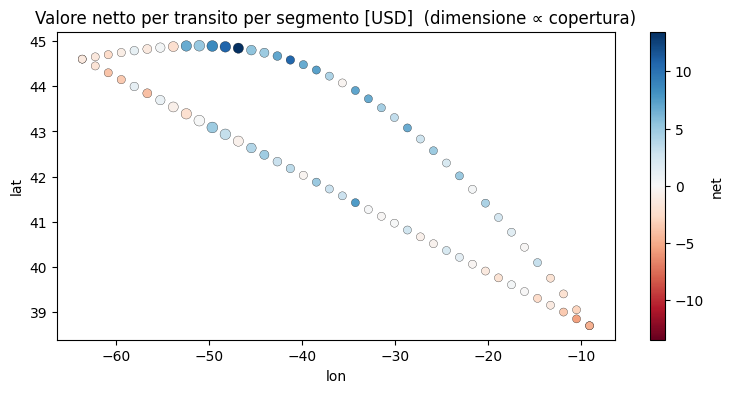

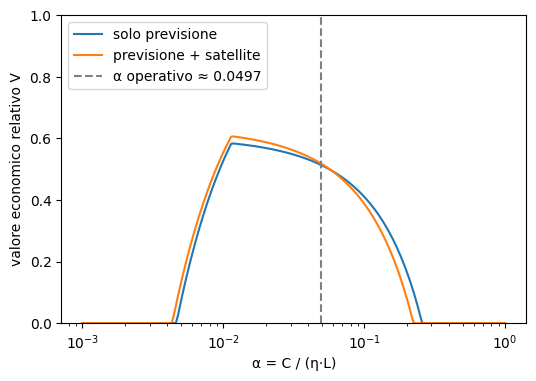

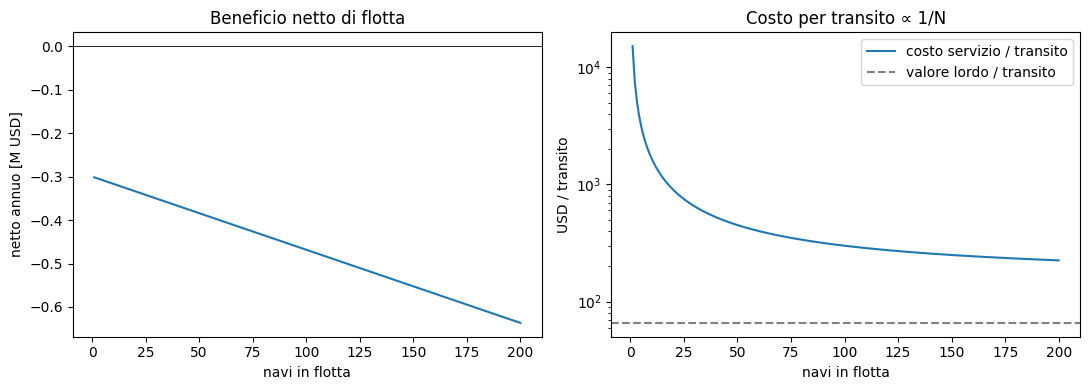

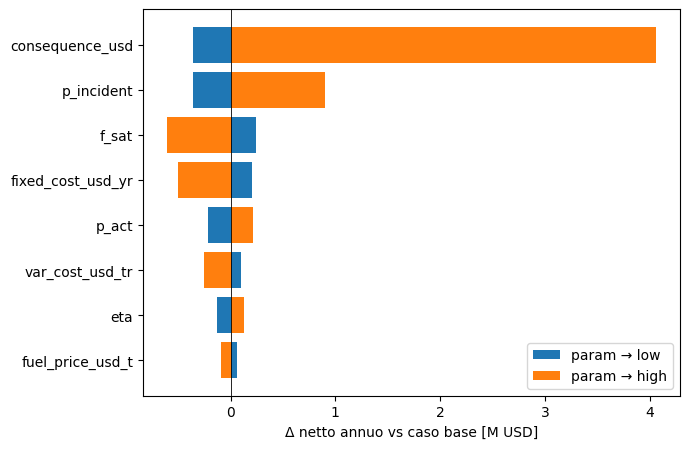

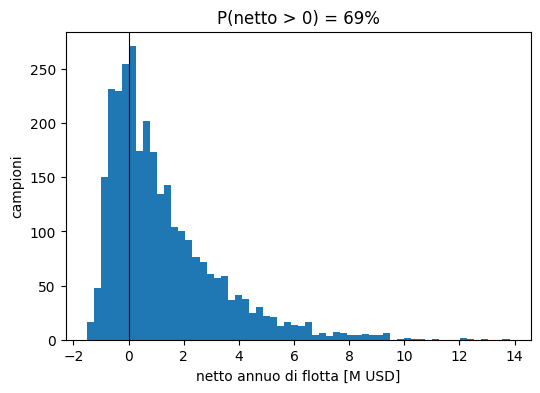

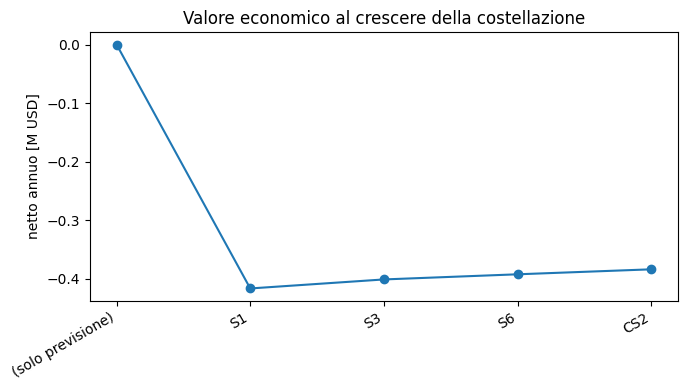

In [16]:
# ── CELLA 16 · Esecuzione di prova (con i dati sintetici della Cella 2) ───────────
seg_raw, routes_raw = make_synthetic_inputs()
res = explore(seg_raw, routes_raw, EconParams(),
              route_ids=None, missions=["S1", "S3", "S6", "CS2"],
              n_ships=50, latency="NRT attuale")

print(res["routes"].round(2), "\n")
print(f"N* di pareggio: {res['n_star']:.1f} navi  |  netto annuo @50 navi: {res['annual_net_usd']:,.0f} USD")
print(res["breakeven"].round(3), "\n")
print(res["mc"]["summary"].round(2), "\n")
print(res["tornado"][["param", "at_low", "at_high"]].round(0), "\n")
print(res["missions_curve"].round(0), "\n")
print(res["latency"].round(1))